# Peramalan Permintaan Kopi Harian per Outlet
## Dasar Perencanaan Persiapan Bahan dan Shift Barista

**Mata Kuliah:** Enterprise Business and Data Analytics (S2 Sistem Informasi, Universitas Telkom)
**Tugas:** Ujian Tengah Semester (take-home project individu)
**Nama / NIM:** Muhammad Aga Hibatulloh / 202022610043
**Kerangka kerja:** KDD (Knowledge Discovery in Databases)

---

### Cara menjalankan

1. Simpan notebook ini di folder `D:\UTS ANALISA BISNIS` (satu folder dengan folder `Anonymous Transactional Dataset`).
2. Pastikan paket berikut terpasang: `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `scipy`, `jinja2` (untuk tampilan tabel).
3. Jalankan dari atas ke bawah (**Restart Kernel & Run All**). Seluruh proses sekitar satu menit.
4. Grafik dan tabel ringkasan tersimpan otomatis di folder `hasil_notebook`.

## Konteks Bisnis dan Tujuan

Data berasal dari sebuah usaha kedai kopi dengan tiga outlet (**SHOP001, SHOP002, SHOP003**) yang mencatat 53.820 struk penjualan selama Januari sampai September 2025. Lebih dari separuh struk (54,0%) berisi minimal satu minuman kopi, sehingga kopi adalah produk utama usaha ini.

Setiap hari, tiap outlet harus memutuskan dua hal tanpa angka pegangan yang jelas:

* **Berapa banyak bahan yang disiapkan** (susu, cold brew, sirup, gula aren, es). Terlalu sedikit berarti pelanggan pulang tanpa membeli; terlalu banyak berarti bahan segar terbuang.
* **Bagaimana membagi tenaga barista** antar jam operasional.

**Tujuan analisis:** meramal jumlah minuman kopi yang akan terjual di setiap outlet untuk hari berikutnya, lalu menerjemahkan ramalan itu menjadi target persiapan harian dan pembagian per shift.

### Pertanyaan yang dijawab

| Spektrum analitik | Pertanyaan |
|---|---|
| Deskriptif | Berapa banyak kopi terjual, di outlet mana, dan pada jam berapa? |
| Diagnostik | Apa yang membuat permintaan naik turun, dan kapan terjadi perubahan tidak biasa? |
| Prediktif | Berapa item kopi yang akan terjual besok di tiap outlet, dan seberapa jauh ramalannya bisa meleset? |
| Preskriptif | Berapa yang perlu disiapkan setiap hari, dan bagaimana membaginya per shift? |

### Alur KDD dalam notebook ini

| Tahap KDD | Isi | Spektrum analitik |
|---|---|---|
| 1. Selection | Memuat data, memilih kolom dan lingkup analisis | - |
| 2. Preprocessing | Memeriksa kualitas data dan mengurai daftar item di setiap struk | - |
| 3. Transformation | Menetapkan definisi kopi, membentuk tabel harian dan fitur model | - |
| 4. Data Mining | Mencari pola, penyebab, dan membangun model peramalan | Deskriptif, Diagnostik, Prediktif |
| 5. Interpretation / Evaluation | Menilai hasil dari sisi bisnis dan menyusun rekomendasi | Preskriptif |

**Sumber data:** _Anonymous Transactional Dataset_ (`Transactions.csv` dan `Products.csv`). _(Lengkapi dengan nama platform, URL, dan tanggal akses.)_

## Persiapan

Sel pertama memuat pustaka dan menentukan lokasi file. Sel kedua mengatur tampilan grafik. Judul dan label grafik ditulis dalam bahasa Inggris supaya bisa langsung dipakai di infografik.

In [34]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
RANDOM_STATE = 42

# Lokasi data. Jika notebook dijalankan dari folder "D:\UTS ANALISA BISNIS", path relatif sudah cukup.
DATA_DIR = Path("Anonymous Transactional Dataset") / "Anonymous Transactional Dataset"
if not DATA_DIR.exists():
    DATA_DIR = Path(r"D:\UTS ANALISA BISNIS\Anonymous Transactional Dataset\Anonymous Transactional Dataset")

# Grafik dan tabel ringkasan disimpan di sini agar bisa dipakai untuk infografik.
OUTPUT_DIR = DATA_DIR.parent.parent / "hasil_notebook"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Folder data  :", DATA_DIR.resolve())
print("Folder output:", OUTPUT_DIR.resolve())

Folder data  : D:\UTS ANALISA BISNIS\Anonymous Transactional Dataset\Anonymous Transactional Dataset
Folder output: D:\UTS ANALISA BISNIS\hasil_notebook


In [35]:
# Gaya grafik dibuat seragam. Warna tiap outlet selalu sama di semua grafik.
OUTLETS = ["SHOP001", "SHOP002", "SHOP003"]
OUTLET_COLORS = {"SHOP001": "#2a78d6", "SHOP002": "#eb6834", "SHOP003": "#1baf7a"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "legend.frameon": False,
    "font.size": 10,
})


def style_axes(ax, title, ylabel="", xlabel=""):
    ax.set_title(title, loc="left", color=INK, fontsize=12, weight="bold", pad=10)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    ax.spines["left"].set_visible(False)
    ax.tick_params(length=0)


def save_figure(fig, name):
    fig.savefig(OUTPUT_DIR / name, dpi=200, bbox_inches="tight")

---
# Tahap 1. Selection (Pemilihan Data)

Tahap ini memuat kedua file dan memilih bagian data yang relevan dengan tujuan analisis.

* `Transactions.csv`: satu baris adalah satu struk. Kolom `Items` berisi daftar produk yang dibeli, dipisahkan koma.
* `Products.csv`: katalog produk berisi nama, varian, kategori, harga, dan deskripsi.

In [36]:
transactions = pd.read_csv(DATA_DIR / "Transactions.csv")
products = pd.read_csv(DATA_DIR / "Products.csv")

print("Transactions.csv:", transactions.shape[0], "baris,", transactions.shape[1], "kolom")
print("Products.csv    :", products.shape[0], "baris,", products.shape[1], "kolom")
display(transactions.head())
display(products.head())

Transactions.csv: 53820 baris, 11 kolom
Products.csv    : 96 baris, 6 kolom


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,"20,720.72","2,279.28",23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,"18,018.02","1,981.98",20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,"39,639.64","4,360.36",44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0
3,SHOP002,2025-01-02,07:14:25,"36,036.04","3,963.96",40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0
4,SHOP002,2025-01-02,07:23:05,"36,036.04","3,963.96",40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0


,ProductId,ProductName,Variant,Category,Price,Description
0,1,Add on Aren,-,Add on,0,"Tambahan sirup gula aren murni, memberikan ras..."
1,2,Add on Simple Syrup,-,Add on,0,Tambahan sirup gula sederhana (air dan gula) s...
2,3,Air Mineral,-,Other,5000,Air minum murni dalam kemasan
3,4,Americano,Hot Houseblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...
4,5,Americano,Ice Houesblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...


In [37]:
display(transactions.dtypes.to_frame("tipe_data"))
display(products["Category"].value_counts().to_frame("jumlah_produk"))

,tipe_data
Outlet,str
Date,str
Time,str
NetSales,float64
Tax,float64
TotalAmount,int64
ReceiptNumber,str
Items,str
TotalItem,int64
PaymentMethod,str


,jumlah_produk
Category,
Coffee,34
Menu Gedhe,19
Other,15
Tea,13
Snacks,9
Add on,6


Kolom yang dipakai:

| Kolom | Kegunaan |
|---|---|
| `Outlet`, `Date`, `Time` | Kapan dan di mana transaksi terjadi |
| `ReceiptNumber`, `Items`, `TotalItem` | Isi struk, untuk menghitung jumlah kopi |
| `NetSales`, `Tax`, `TotalAmount` | Hanya untuk pemeriksaan konsistensi nilai transaksi |
| Katalog: `ProductName`, `Variant`, `Category`, `Price`, `Description` | Menentukan item mana yang termasuk kopi |

`PaymentMethod` dan `UseLoyaltyCard` tidak dipakai karena tidak berkaitan dengan jumlah kopi yang perlu disiapkan. Dataset tidak memiliki ID pelanggan, sehingga analisis ini tidak membahas perilaku pelanggan perorangan.

In [38]:
# Kolom yang dipakai untuk analisis permintaan kopi.
transactions = transactions[["Outlet", "Date", "Time", "ReceiptNumber", "Items", "TotalItem",
                             "NetSales", "Tax", "TotalAmount"]].copy()
products = products[["ProductId", "ProductName", "Variant", "Category", "Price", "Description"]].copy()

---
# Tahap 2. Preprocessing (Pemeriksaan dan Pembersihan Data)

Sebelum dianalisis, data diperiksa dari empat sisi: sel kosong, struk ganda, kecocokan nilai uang, dan kelengkapan tanggal.

In [39]:
quality = pd.Series({
    "Sel kosong di Transactions": int(transactions.isna().sum().sum()),
    "Sel kosong di Products": int(products.isna().sum().sum()),
    "Nomor struk duplikat": int(transactions["ReceiptNumber"].duplicated().sum()),
    "Selisih terbesar NetSales + Tax vs TotalAmount": float((transactions["NetSales"] + transactions["Tax"]
                                                             - transactions["TotalAmount"]).abs().max()),
}, dtype=object)
display(quality.to_frame("hasil"))

,hasil
Sel kosong di Transactions,0
Sel kosong di Products,0
Nomor struk duplikat,0
Selisih terbesar NetSales + Tax vs TotalAmount,0.00


In [40]:
transactions["Date"] = pd.to_datetime(transactions["Date"], format="%Y-%m-%d")
transactions["Hour"] = pd.to_datetime(transactions["Time"], format="%H:%M:%S").dt.hour

all_dates = pd.date_range(transactions["Date"].min(), transactions["Date"].max(), freq="D")
coverage = (transactions.groupby("Outlet")
            .agg(tanggal_awal=("Date", "min"), tanggal_akhir=("Date", "max"),
                 hari_beroperasi=("Date", "nunique"), jam_pertama=("Time", "min"), jam_terakhir=("Time", "max"),
                 jumlah_struk=("ReceiptNumber", "count")))
coverage["hari_kalender"] = len(all_dates)
display(coverage)

,tanggal_awal,tanggal_akhir,hari_beroperasi,jam_pertama,jam_terakhir,jumlah_struk,hari_kalender
Outlet,,,,,,,
SHOP001,2025-01-02,2025-09-30,272,07:00:02,22:59:59,26250,272
SHOP002,2025-01-02,2025-09-30,272,07:00:10,22:59:51,10817,272
SHOP003,2025-01-02,2025-09-30,272,09:00:02,22:59:59,16753,272


> **Kesimpulan:** Ketiga outlet beroperasi penuh setiap hari selama 272 hari (2 Januari – 30 September 2025) tanpa ada tanggal yang kosong. Perlu dicatat bahwa **SHOP003 baru buka pukul 09.00**, sedangkan SHOP001 dan SHOP002 sudah buka sejak pukul 07.00. Perbedaan jam buka ini nanti akan memengaruhi perbandingan penjualan pada shift pagi.


### Mengurai daftar item

Kolom `Items` berisi beberapa produk dalam satu sel, misalnya `"Friendly Coffee (Hot), Shakencano"`. Setiap produk dipisah menjadi satu baris, lalu dicocokkan dengan katalog. Nama di struk mengikuti pola `NamaProduk (Varian)`, atau hanya `NamaProduk` bila variannya `-`.

Sebagai kontrol, jumlah item hasil uraian dibandingkan dengan kolom `TotalItem` di setiap struk.

In [41]:
# Nama item di struk mengikuti format katalog: "NamaProduk (Varian)", atau "NamaProduk" bila varian "-".
products["ItemLabel"] = np.where(products["Variant"].eq("-"),
                                 products["ProductName"],
                                 products["ProductName"] + " (" + products["Variant"] + ")")
print("Label katalog unik:", products["ItemLabel"].is_unique)

# Satu struk bisa berisi beberapa item yang dipisah koma. Setiap item dijadikan satu baris.
items = (transactions[["Outlet", "Date", "Time", "Hour", "ReceiptNumber", "Items"]]
         .assign(ItemLabel=transactions["Items"].str.split(","))
         .explode("ItemLabel"))
items["ItemLabel"] = items["ItemLabel"].str.strip()
items = items.drop(columns="Items").merge(products, on="ItemLabel", how="left")

parsed_per_receipt = items.groupby("ReceiptNumber").size().reindex(transactions["ReceiptNumber"])
check = pd.Series({
    "Total baris item": len(items),
    "Item yang tidak ditemukan di katalog": int(items["ProductId"].isna().sum()),
    "Struk dengan jumlah item tidak sama dengan TotalItem": int(
        (parsed_per_receipt.to_numpy() != transactions["TotalItem"].to_numpy()).sum()),
}, dtype=object)
display(check.to_frame("hasil"))

Label katalog unik: True


,hasil
Total baris item,61973
Item yang tidak ditemukan di katalog,0
Struk dengan jumlah item tidak sama dengan TotalItem,0


> **Kesimpulan:** Data sangat bersih dan siap dipakai. Tidak ada sel kosong, tidak ada nomor struk ganda, nilai `NetSales + Tax` selalu cocok dengan `TotalAmount` (selisih 0), seluruh **61.973 item** berhasil dicocokkan 100% dengan katalog produk, dan jumlah item di tiap struk selalu sesuai dengan angka di kolom `TotalItem`. Tidak ada baris data yang perlu dibuang.


---
# Tahap 3. Transformation (Pembentukan Data Analisis)

### 3.1 Definisi minuman kopi

Kategori katalog tidak bisa dipakai begitu saja. Kategori `Coffee` memuat minuman tanpa kopi (contoh: *Biru*, minuman lemon dan soda), sementara banyak minuman kopi ukuran besar masuk kategori `Menu Gedhe`.

Aturan yang dipakai: **sebuah produk dihitung sebagai kopi bila deskripsinya menyebut "kopi", "coffee", atau "espresso", dan kategorinya `Coffee` atau `Menu Gedhe`.** Add-on (misalnya tambahan shot) tidak dihitung karena bukan minuman tersendiri.

In [42]:
coffee_words = r"\b(?:kopi|coffee|espresso)\b"
products["IsCoffee"] = (products["Description"].str.contains(coffee_words, case=False, regex=True)
                        & products["Category"].isin(["Coffee", "Menu Gedhe"]))

print("Produk kopi:", int(products["IsCoffee"].sum()), "dari", len(products), "produk")
excluded = products.loc[products["Category"].isin(["Coffee", "Menu Gedhe"]) & ~products["IsCoffee"],
                        ["ProductName", "Variant", "Category", "Description"]]
print("\nProduk di kategori Coffee/Menu Gedhe yang tidak dihitung sebagai kopi:")
display(excluded)

Produk kopi: 47 dari 96 produk

Produk di kategori Coffee/Menu Gedhe yang tidak dihitung sebagai kopi:


,ProductName,Variant,Category,Description
19,Biru,-,Coffee,Minuman menyegarkan berwarna biru cerah dengan...
20,Biru (Gedhe),-,Menu Gedhe,Minuman ukuran besar menyegarkan berwarna biru...
36,Chocolate (Gedhe),-,Menu Gedhe,Minuman ukuran besar dari cokelat klasik denga...
53,Green Thai Tea (Gedhe),-,Menu Gedhe,Minuman ukuran besar teh hijau ala Thailand ya...
68,Matcha Latte (Gedhe),-,Menu Gedhe,Minuman latte ukuran besar dari perpaduan matc...
85,Thai Tea (Gedhe),-,Menu Gedhe,Minuman ukuran besar dari teh hitam ala Thaila...


> **Kesimpulan:** Dari 96 produk di katalog, terpilih **47 produk minuman kopi** (total **31.068 gelas terjual** di **29.044 struk**, atau **54,0%** dari seluruh transaksi). Enam produk di kategori `Coffee` dan `Menu Gedhe` yang dikeluarkan memang bukan minuman kopi (minuman soda lemon *Biru*, cokelat, *Thai tea*, dan *matcha* tanpa espresso).


### 3.2 Tabel item kopi

Setiap item kopi diberi label shift kerja agar hasil analisis bisa langsung dipakai untuk penjadwalan:

| Shift | Jam |
|---|---|
| Morning | 07.00 - 10.59 (SHOP003 mulai 09.00) |
| Midday | 11.00 - 14.59 |
| Afternoon | 15.00 - 17.59 |
| Evening | 18.00 - 22.59 |

In [43]:
items = items.merge(products[["ItemLabel", "IsCoffee"]], on="ItemLabel", how="left")
coffee = items.loc[items["IsCoffee"]].copy()

# Pembagian shift kerja yang dipakai di seluruh analisis.
coffee["Shift"] = pd.cut(coffee["Hour"], bins=[-1, 10, 14, 17, 23],
                         labels=["Morning 07-10", "Midday 11-14", "Afternoon 15-17", "Evening 18-22"])
coffee["Month"] = coffee["Date"].dt.to_period("M")

print("Baris item kopi       :", f"{len(coffee):,}")
print("Struk yang berisi kopi:", f"{coffee['ReceiptNumber'].nunique():,}",
      f"({coffee['ReceiptNumber'].nunique() / len(transactions):.1%} dari semua struk)")
display(coffee.head())

Baris item kopi       : 31,068
Struk yang berisi kopi: 29,044 (54.0% dari semua struk)


,Outlet,Date,Time,Hour,ReceiptNumber,ItemLabel,ProductId,ProductName,Variant,Category,Price,Description,IsCoffee,Shift,Month
0,SHOP001,2025-01-02,07:01:05,7,SHOP001JAN2500001,Basic Latte (Ice Arabica),18,Basic Latte,Ice Arabica,Coffee,23000,Minuman klasik dengan 1 shot espresso dari bij...,True,Morning 07-10,2025-01
1,SHOP001,2025-01-02,07:04:11,7,SHOP001JAN2500002,BLACK (Houseblend),11,BLACK,Houseblend,Menu Gedhe,20000,"Minuman kopi hitam murni dalam ukuran besar, d...",True,Morning 07-10,2025-01
2,SHOP002,2025-01-02,07:10:46,7,SHOP002JAN2500001,Friendly Coffee (Hot),49,Friendly Coffee,Hot,Coffee,23000,Minuman kopi susu dengan perpaduan single shot...,True,Morning 07-10,2025-01
3,SHOP002,2025-01-02,07:10:46,7,SHOP002JAN2500001,Shakencano,79,Shakencano,-,Coffee,21000,Minuman dingin perpaduan espresso dan gula are...,True,Morning 07-10,2025-01
4,SHOP002,2025-01-02,07:14:25,7,SHOP002JAN2500002,BLACK (Arabica),12,BLACK,Arabica,Menu Gedhe,20000,"Minuman kopi hitam murni dalam ukuran besar, d...",True,Morning 07-10,2025-01


### 3.3 Tabel harian dan fitur model

Unit analisis untuk peramalan adalah **satu outlet pada satu hari**. Targetnya adalah `CoffeeItems`, yaitu jumlah item kopi yang terjual di outlet tersebut pada hari itu.

Fitur dibentuk hanya dari data **sampai hari sebelumnya**, karena ramalan untuk besok dibuat setelah outlet tutup malam ini. Dengan begitu model tidak memakai informasi yang belum tersedia saat ramalan dibuat.

| Fitur | Arti |
|---|---|
| `OutletCode` | Kode outlet (0, 1, 2) |
| `DayOfWeek` | Hari dalam minggu (0 = Senin) |
| `Lag1` | Penjualan kopi kemarin |
| `Lag7` | Penjualan kopi pada hari yang sama minggu lalu |
| `Avg7` | Rata-rata penjualan 7 hari terakhir |
| `Avg28` | Rata-rata penjualan 28 hari terakhir |
| `Std7` | Simpangan baku 7 hari terakhir (seberapa bergejolak penjualan minggu ini) |

Alasan pemilihan tiap fitur dijelaskan dengan data pada bagian diagnostik (4.2).

In [44]:
# Tabel harian: satu baris = satu outlet pada satu tanggal.
grid = pd.MultiIndex.from_product([OUTLETS, all_dates], names=["Outlet", "Date"]).to_frame(index=False)
daily = (coffee.groupby(["Outlet", "Date"]).size().rename("CoffeeItems").reset_index())
daily = grid.merge(daily, on=["Outlet", "Date"], how="left").fillna({"CoffeeItems": 0})
receipts_daily = transactions.groupby(["Outlet", "Date"]).size().rename("Receipts").reset_index()
daily = daily.merge(receipts_daily, on=["Outlet", "Date"], how="left").fillna({"Receipts": 0})
daily = daily.sort_values(["Outlet", "Date"]).reset_index(drop=True)

# Fitur model. Semua fitur hanya memakai data sampai hari sebelumnya (shift(1)),
# jadi model tidak "mengintip" angka hari yang sedang diramal.
by_outlet = daily.groupby("Outlet")["CoffeeItems"]
daily["OutletCode"] = daily["Outlet"].map({o: i for i, o in enumerate(OUTLETS)})
daily["DayOfWeek"] = daily["Date"].dt.dayofweek
daily["Lag1"] = by_outlet.shift(1)
daily["Lag7"] = by_outlet.shift(7)
daily["Avg7"] = by_outlet.transform(lambda s: s.shift(1).rolling(7).mean())
daily["Avg28"] = by_outlet.transform(lambda s: s.shift(1).rolling(28).mean())
daily["Std7"] = by_outlet.transform(lambda s: s.shift(1).rolling(7).std())

FEATURES = ["OutletCode", "DayOfWeek", "Lag1", "Lag7", "Avg7", "Avg28", "Std7"]
display(daily.dropna().head(8))

,Outlet,Date,CoffeeItems,Receipts,OutletCode,DayOfWeek,Lag1,Lag7,Avg7,Avg28,Std7
28,SHOP001,2025-01-30,44,90,0,3,49.00,61.00,53.14,51.57,5.61
29,SHOP001,2025-01-31,46,98,0,4,44.00,57.00,50.71,51.64,5.31
30,SHOP001,2025-02-01,61,111,0,5,46.00,51.00,49.14,51.04,4.74
31,SHOP001,2025-02-02,48,102,0,6,61.00,55.00,50.57,51.32,6.55
32,SHOP001,2025-02-03,53,105,0,0,48.00,44.00,49.57,51.25,6.29
33,SHOP001,2025-02-04,64,109,0,1,53.00,55.00,50.86,51.68,5.87
34,SHOP001,2025-02-05,68,108,0,2,64.00,49.00,52.14,51.93,7.65
35,SHOP001,2025-02-06,47,98,0,3,68.00,44.00,54.86,52.18,9.49


---
# Tahap 4. Data Mining

## 4.1 Analitik Deskriptif: Apa yang terjadi?

In [45]:
total_days = daily.groupby("Outlet")["Date"].nunique()
summary_outlet = pd.DataFrame({
    "total_item_kopi": coffee.groupby("Outlet").size(),
    "rata2_kopi_per_hari": coffee.groupby("Outlet").size() / total_days,
    "rata2_struk_per_hari": transactions.groupby("Outlet").size() / total_days,
})
summary_outlet["porsi_dari_total_kopi"] = summary_outlet["total_item_kopi"] / summary_outlet["total_item_kopi"].sum()
display(summary_outlet.style.format({"total_item_kopi": "{:,.0f}", "rata2_kopi_per_hari": "{:.1f}",
                                     "rata2_struk_per_hari": "{:.1f}", "porsi_dari_total_kopi": "{:.1%}"}))
print(f"Rata-rata seluruh outlet: {daily['CoffeeItems'].mean():.1f} item kopi per outlet per hari")

,total_item_kopi,rata2_kopi_per_hari,rata2_struk_per_hari,porsi_dari_total_kopi
Outlet,,,,
SHOP001,"15,119",55.6,96.5,48.7%
SHOP002,"6,337",23.3,39.8,20.4%
SHOP003,"9,612",35.3,61.6,30.9%


Rata-rata seluruh outlet: 38.1 item kopi per outlet per hari


> **Kesimpulan:** Ukuran ketiga outlet cukup jauh berbeda. **SHOP001** adalah cabang terbesar yang menyumbang hampir separuh penjualan kopi (**15.119 gelas** atau **48,7%**, rata-rata **55,6 gelas/hari**), disusul **SHOP003** (**9.612 gelas** atau **30,9%**, rata-rata **35,3 gelas/hari**), dan yang terkecil **SHOP002** (**6.337 gelas** atau **20,4%**, rata-rata **23,3 gelas/hari**). Secara keseluruhan, rata-rata penjualan adalah **38,1 gelas kopi per outlet per hari**.


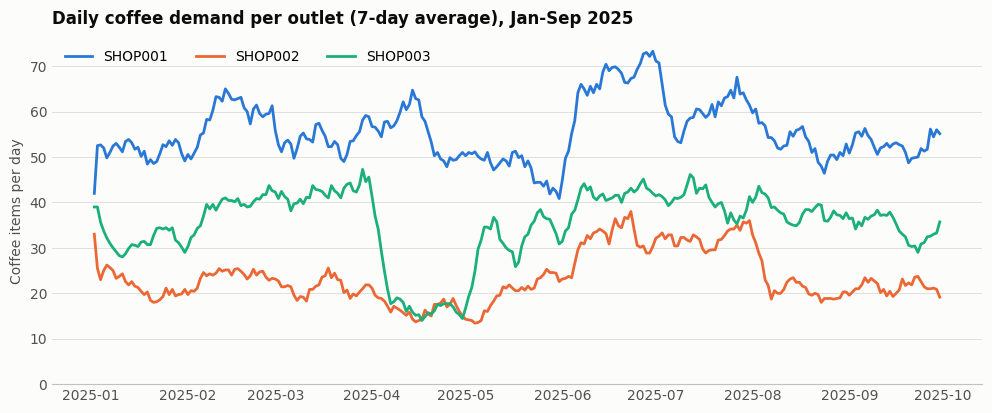

In [46]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for outlet in OUTLETS:
    s = daily.loc[daily["Outlet"] == outlet].set_index("Date")["CoffeeItems"]
    ax.plot(s.index, s.rolling(7, min_periods=1).mean(), color=OUTLET_COLORS[outlet], linewidth=2, label=outlet)
style_axes(ax, "Daily coffee demand per outlet (7-day average), Jan-Sep 2025", "Coffee items per day")
ax.set_ylim(bottom=0)
ax.legend(ncol=3, loc="upper left")
save_figure(fig, "01_daily_trend.png")
plt.show()

> **Kesimpulan:** Penjualan kopi tidak datar sepanjang tahun. Terlihat penurunan tajam di **SHOP003** dan **SHOP002** pada bulan April, serta kenaikan tinggi di ketiga outlet pada bulan Juni sampai Juli. Sementara itu, **SHOP001** cenderung stabil di bulan Maret–April saat dua cabang lainnya turun.


In [47]:
top_products = (coffee.groupby("ItemLabel").size().sort_values(ascending=False)
                .rename("item_terjual").to_frame())
top_products["porsi"] = top_products["item_terjual"] / len(coffee)
display(top_products.head(10).style.format({"porsi": "{:.1%}"}))
print("Jumlah produk kopi yang terjual:", len(top_products))
print(f"Porsi 10 produk teratas: {top_products['porsi'].head(10).sum():.1%}")

,item_terjual,porsi
ItemLabel,,
Friendly Coffee (Ice),715,2.3%
Friendly Coffee (Hot),708,2.3%
Americano (Hot Arabica),706,2.3%
BLACK (Houseblend),704,2.3%
Butterscotch,701,2.3%
Shakencano,699,2.2%
Not Tiramisu Latte (Gedhe),698,2.2%
Hazelnut Latte (Gedhe),692,2.2%
WHITE (Houseblend),688,2.2%


Jumlah produk kopi yang terjual: 47
Porsi 10 produk teratas: 22.5%


> **Kesimpulan:** Penjualan kopi tersebar sangat merata di 47 menu. Menu paling laris (*Friendly Coffee Ice*, 715 gelas) hanya menyumbang **2,3%** dari total penjualan kopi, dan 10 menu teratas kalau digabung hanya **22,5%**. Karena tidak ada satu menu yang mendominasi dan bahan dasarnya sama (biji kopi, susu segar, es, sirup), perencanaan persiapan bahan jauh lebih efektif dihitung untuk **total gelas kopi per outlet** daripada diramal satu per satu per menu.


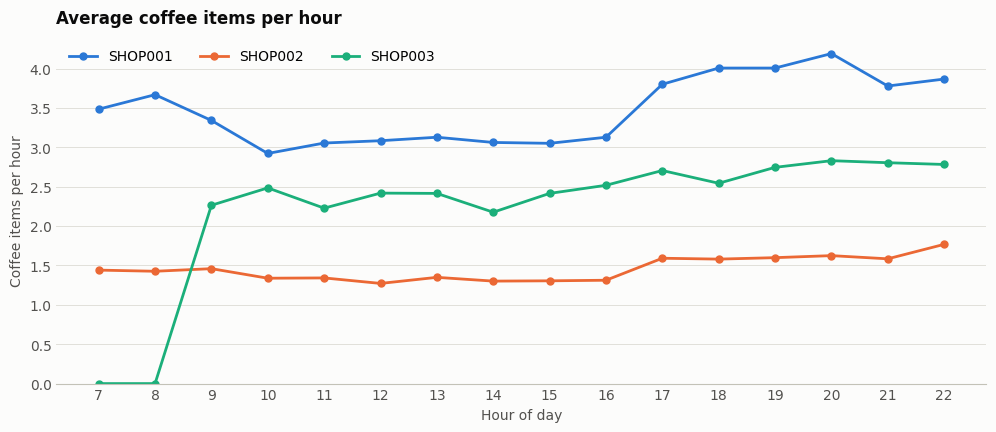

Porsi permintaan kopi per shift:


Shift,Morning 07-10,Midday 11-14,Afternoon 15-17,Evening 18-22
Outlet,,,,
SHOP001,24.1%,22.2%,18.0%,35.7%
SHOP002,24.3%,22.6%,18.1%,35.0%
SHOP003,13.4%,26.1%,21.6%,38.8%


Rata-rata item kopi per jam di setiap shift:


Shift,Morning 07-10,Midday 11-14,Afternoon 15-17,Evening 18-22
Outlet,,,,
SHOP001,3.35,3.08,3.33,3.97
SHOP002,1.42,1.32,1.40,1.63
SHOP003,2.38,2.31,2.55,2.74


In [48]:
hourly = coffee.groupby(["Outlet", "Hour"]).size().unstack(0).fillna(0) / len(all_dates)

fig, ax = plt.subplots(figsize=(12, 4.5))
for outlet in OUTLETS:
    ax.plot(hourly.index, hourly[outlet], color=OUTLET_COLORS[outlet], linewidth=2,
            marker="o", markersize=5, label=outlet)
style_axes(ax, "Average coffee items per hour", "Coffee items per hour", "Hour of day")
ax.set_xticks(range(7, 23))
ax.set_ylim(bottom=0)
ax.legend(ncol=3, loc="upper left")
save_figure(fig, "02_hourly_profile.png")
plt.show()

shift_share = pd.crosstab(coffee["Outlet"], coffee["Shift"], normalize="index")
print("Porsi permintaan kopi per shift:")
display(shift_share.style.format("{:.1%}"))

# Panjang shift berbeda (malam 5 jam, sore 3 jam), jadi dibandingkan juga per jam buka.
open_hours = coffee.groupby(["Outlet", "Shift"], observed=True)["Hour"].nunique()
per_hour = (coffee.groupby(["Outlet", "Shift"], observed=True).size() / len(all_dates) / open_hours).unstack()
print("Rata-rata item kopi per jam di setiap shift:")
display(per_hour.round(2))

> **Kesimpulan:**
> * **Shift malam (18.00–22.59) adalah waktu paling ramai** di semua outlet, menyumbang **35,0% – 38,8%** penjualan kopi harian (rata-rata gabungan **36,5%**).
> * Walaupun shift malam durasinya paling panjang (5 jam), jika dihitung rata-rata **per jam buka**, permintaan malam hari tetap paling tinggi (SHOP001: **3,97 gelas/jam**, SHOP003: **2,74 gelas/jam**, SHOP002: **1,63 gelas/jam**).
> * Porsi shift pagi di SHOP003 terlihat kecil (**13,4%**) semata-mata karena cabang ini baru buka pukul 09.00 (hanya 2 jam di shift pagi). Jika dilihat per jam, keramaian pagi di SHOP003 (2,38 gelas/jam) setara dengan siang hari (2,31 gelas/jam).


In [49]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = daily.groupby(["DayOfWeek", "Outlet"])["CoffeeItems"].mean().unstack()
weekday.index = weekday_names
display(weekday)
spread = (weekday.max() - weekday.min()) / weekday.mean()
print("Selisih hari tertinggi dan terendah, dibanding rata-rata outlet:")
print(spread.map("{:.1%}".format).to_string())

Outlet,SHOP001,SHOP002,SHOP003
Mon,55.18,22.92,35.74
Tue,56.87,23.03,33.51
Wed,55.13,22.53,34.82
Thu,54.85,25.28,35.13
Fri,54.62,24.08,36.95
Sat,55.21,22.44,34.21
Sun,57.23,22.79,37.00


Selisih hari tertinggi dan terendah, dibanding rata-rata outlet:
Outlet
SHOP001     4.7%
SHOP002    12.2%
SHOP003     9.9%


> **Kesimpulan:** Perbedaan penjualan antarhari (Senin sampai Minggu) ternyata sangat kecil. Selisih antara hari paling ramai dan hari paling sepi hanya **4,7%** di SHOP001, **12,2%** di SHOP002, dan **9,9%** di SHOP003 dibanding rata-rata cabangnya. Artinya, faktor nama hari bukanlah penyebab utama naik-turunnya permintaan kopi di kafe ini.


## 4.2 Analitik Diagnostik: Mengapa itu terjadi?

Bagian ini mencari faktor yang menjelaskan naik turunnya penjualan kopi. Karena datanya observasional, temuan di sini menunjukkan **keterkaitan**, bukan bukti sebab-akibat.

### a. Kopi mengikuti jumlah pengunjung, bukan perubahan selera

In [50]:
monthly = (daily.assign(Month=daily["Date"].dt.to_period("M"))
           .groupby(["Outlet", "Month"])[["CoffeeItems", "Receipts"]].sum())
monthly["CoffeeShare"] = (coffee.groupby(["Outlet", "Month"])["ReceiptNumber"].nunique()
                          / monthly["Receipts"])
print("Porsi struk yang berisi kopi per bulan:")
display(monthly["CoffeeShare"].unstack(0).style.format("{:.1%}"))

corr = daily.groupby("Outlet")[["Receipts", "CoffeeItems"]].corr().xs("Receipts", level=1)["CoffeeItems"]
print("Korelasi jumlah struk harian dengan item kopi harian:")
print(corr.round(3).to_string())

Porsi struk yang berisi kopi per bulan:


Outlet,SHOP001,SHOP002,SHOP003
Month,,,
2025-01,53.8%,56.9%,52.8%
2025-02,53.4%,53.5%,54.2%
2025-03,54.0%,56.8%,54.2%
2025-04,55.3%,53.8%,52.3%
2025-05,52.1%,54.0%,54.4%
2025-06,53.9%,55.0%,51.9%
2025-07,52.6%,54.6%,54.7%
2025-08,53.2%,53.1%,55.0%
2025-09,54.8%,55.7%,54.5%


Korelasi jumlah struk harian dengan item kopi harian:
Outlet
SHOP001   0.84
SHOP002   0.87
SHOP003   0.91


> **Kesimpulan:** Porsi struk yang membeli kopi selalu stabil di kisaran **52,1% – 56,9%** setiap bulan di semua cabang, dan jumlah struk harian berkaitan sangat kuat dengan jumlah kopi yang terjual (korelasi **0,84 – 0,91**). Artinya, ketika penjualan kopi naik atau turun, penyebab utamanya adalah **jumlah pengunjung kafe yang memang sedang ramai atau sepi**, bukan karena pelanggan beralih dari kopi ke minuman lain.

### b. Bulan yang tidak biasa

Indeks di bawah membandingkan rata-rata penjualan harian tiap bulan dengan bulan normal (median) di outlet yang sama. Nilai 1,00 berarti normal, 0,43 berarti hanya 43% dari biasanya.


In [51]:
# Indeks bulanan: rata-rata kopi per hari pada bulan itu dibagi median bulanan outlet yang sama.
per_day = daily.assign(Month=daily["Date"].dt.to_period("M")).groupby(["Outlet", "Month"])["CoffeeItems"].mean()
month_index = (per_day / per_day.groupby("Outlet").transform("median")).unstack(0)
display(month_index.style.format("{:.2f}").background_gradient(cmap="RdBu", vmin=0.4, vmax=1.6))

Outlet,SHOP001,SHOP002,SHOP003
Month,,,
2025-01,0.95,1.01,0.83
2025-02,1.12,1.13,1.08
2025-03,1.00,1.00,1.13
2025-04,1.02,0.74,0.43
2025-05,0.86,0.97,0.87
2025-06,1.28,1.54,1.13
2025-07,1.11,1.53,1.08
2025-08,0.98,0.95,1.00
2025-09,0.98,1.00,0.91


> **Kesimpulan:** Tabel indeks bulanan menunjukkan tiga kejadian mencolok:
> 1. **Penurunan tajam bulan April di SHOP003 dan SHOP002:** penjualan SHOP003 turun menjadi **43%** dari normal (indeks **0,43**) dan SHOP002 menjadi **74%** (**0,74**), sedangkan SHOP001 tetap normal (**1,02**).
> 2. **Kenaikan bulan Juni–Juli di semua cabang:** penjualan melonjak terutama di SHOP002 (mencapai **1,54** dan **1,53** kali normal) serta SHOP001 pada bulan Juni (**1,28**).
> 3. **Bulan Maret terlihat normal secara total bulanan** (indeks 1,00 – 1,13), tetapi sebenarnya terjadi pergeseran jam belanja yang besar, seperti terlihat pada grafik siang vs sore-malam di bawah.

### c. Pola sebelum dan sesudah pukul 16.00

Grafik berikut membandingkan penjualan kopi sebelum pukul 16.00 dan sesudahnya, per bulan dan per outlet.


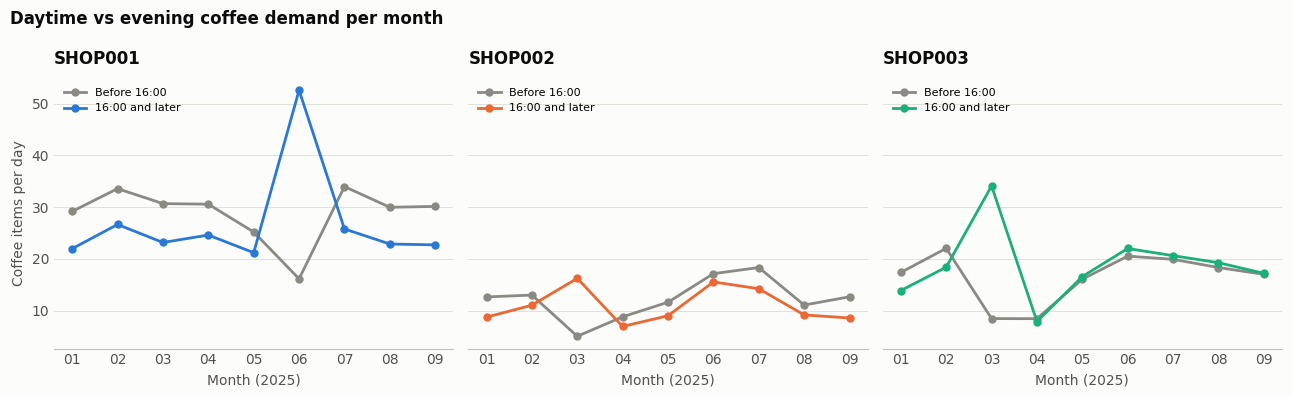

Period           Before 16:00  16:00 and later
Outlet  Month                                 
SHOP001 2025-02         33.60            26.60
        2025-03         30.70            23.20
        2025-04         30.60            24.60
        2025-05         25.20            21.20
        2025-06         16.10            52.60
SHOP002 2025-02         13.00            11.00
        2025-03          5.00            16.20
        2025-04          8.80             6.90
        2025-05         11.60             9.00
        2025-06         17.10            15.50
SHOP003 2025-02         22.00            18.40
        2025-03          8.50            34.10
        2025-04          8.40             7.90
        2025-05         16.10            16.60
        2025-06         20.50            22.00

In [52]:
# Pembagian siang (sebelum 16.00) dan sore-malam (16.00 ke atas) per bulan.
coffee["Period"] = np.where(coffee["Hour"] < 16, "Before 16:00", "16:00 and later")
days_in_month = daily.assign(Month=daily["Date"].dt.to_period("M")).groupby(["Outlet", "Month"])["Date"].nunique()
day_evening = coffee.groupby(["Outlet", "Month", "Period"]).size().unstack("Period")
day_evening = day_evening.div(days_in_month, axis=0)[["Before 16:00", "16:00 and later"]]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
months = [str(m) for m in day_evening.loc["SHOP001"].index]
x = np.arange(len(months))
for ax, outlet in zip(axes, OUTLETS):
    d = day_evening.loc[outlet]
    ax.plot(x, d["Before 16:00"], color="#8a8983", linewidth=2, marker="o", markersize=5, label="Before 16:00")
    ax.plot(x, d["16:00 and later"], color=OUTLET_COLORS[outlet], linewidth=2, marker="o", markersize=5,
            label="16:00 and later")
    ax.set_xticks(x, [m[5:] for m in months])
    style_axes(ax, outlet, "Coffee items per day" if outlet == "SHOP001" else "", "Month (2025)")
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Daytime vs evening coffee demand per month", x=0.01, ha="left", weight="bold", color=INK)
fig.tight_layout()
save_figure(fig, "03_daytime_vs_evening.png")
plt.show()

display(day_evening.loc[(slice(None), [pd.Period("2025-02"), pd.Period("2025-03"), pd.Period("2025-04"),
                                       pd.Period("2025-05"), pd.Period("2025-06")]), :].round(1))

> **Kesimpulan:**
> * **Pergeseran jam belanja di bulan Maret (bertepatan dengan Ramadan, 1–30 Maret 2025):** Di SHOP002 dan SHOP003, penjualan siang hari (sebelum 16.00) turun sekitar **61%** (SHOP002 dari **13,0 menjadi 5,0 gelas/hari**; SHOP003 dari **22,0 menjadi 8,5 gelas/hari**). Sebaliknya, penjualan sore-malam melonjak tinggi menjelang dan sesudah waktu berbuka (SHOP002 naik dari **11,0 ke 16,2**; SHOP003 hampir dua kali lipat dari **18,4 ke 34,1 gelas/hari**).
> * **Penurunan bulan April (setelah Idulfitri 31 Maret 2025):** Baik penjualan siang maupun malam sama-sama turun selama sebulan penuh di SHOP002 dan SHOP003, sedangkan **SHOP001 tidak terdampak Ramadan maupun Lebaran**.
> * **Lonjakan malam di SHOP001 pada bulan Juni:** Penjualan sore-malam naik lebih dari dua kali lipat (dari **21,2 menjadi 52,6 gelas/hari**), sementara siang harinya turun (25,2 ke 16,1). Karena tidak ada keterangan acara atau perubahan jam buka di dataset, keanehan ini harus dikonfirmasi ke pengelola cabang.

### d. Seberapa acak penjualan harian?

Jika penjualan harian hanya bervariasi secara acak di sekitar rata-ratanya (seperti jumlah pelanggan yang datang secara independen), simpangan bakunya akan mendekati akar dari rata-rata. Uji ini dilakukan pada delapan minggu terakhir yang polanya stabil.


In [53]:
# Seberapa acak permintaan harian? Diuji pada 8 minggu terakhir yang polanya stabil.
recent = daily.loc[daily["Date"] >= daily["Date"].max() - pd.Timedelta(days=55)]
noise = recent.groupby("Outlet")["CoffeeItems"].agg(rata2="mean", simpangan_baku="std")
noise["akar_rata2"] = np.sqrt(noise["rata2"])
noise["rasio"] = noise["simpangan_baku"] / noise["akar_rata2"]
display(noise)

autocorr = pd.DataFrame({
    "korelasi_dengan_kemarin": daily.groupby("Outlet").apply(lambda d: d["CoffeeItems"].corr(d["Lag1"])),
    "korelasi_dengan_minggu_lalu": daily.groupby("Outlet").apply(lambda d: d["CoffeeItems"].corr(d["Lag7"])),
    "korelasi_dengan_rata2_7_hari": daily.groupby("Outlet").apply(lambda d: d["CoffeeItems"].corr(d["Avg7"])),
})
display(autocorr.round(3))

,rata2,simpangan_baku,akar_rata2,rasio
Outlet,,,,
SHOP001,52.45,7.56,7.24,1.04
SHOP002,20.88,4.48,4.57,0.98
SHOP003,35.59,6.38,5.97,1.07


,korelasi_dengan_kemarin,korelasi_dengan_minggu_lalu,korelasi_dengan_rata2_7_hari
Outlet,,,
SHOP001,0.31,0.20,0.45
SHOP002,0.47,0.40,0.61
SHOP003,0.59,0.42,0.65


> **Kesimpulan:**
> * Rasio simpangan baku terhadap akar rata-rata mendekati **1,0** di ketiga cabang (**0,98 – 1,07**). Artinya, pada minggu-minggu yang normal, **naik-turun harian sebesar 5 – 7 gelas per hari adalah variasi acak kedatangan pembeli** yang tidak bisa ditebak oleh model apa pun dan harus diatasi dengan stok cadangan (*buffer*).
> * Penjualan hari ini paling kuat hubungannya dengan **rata-rata 7 hari terakhir (`Avg7`, korelasi 0,45 – 0,65)** dibanding dengan penjualan kemarin saja (**0,31 – 0,59**) atau hari yang sama minggu lalu (**0,20 – 0,42**). Rata-rata 7 hari mampu meredam keacakan harian sekaligus mengikuti perubahan tren mingguan.

### Ringkasan diagnostik dan dampaknya pada rancangan model

| Temuan diagnostik | Konsekuensi untuk model dan perencanaan |
|---|---|
| Skala penjualan berbeda jauh antar-outlet | Masukkan fitur `OutletCode`, dan hitung stok cadangan (*buffer*) secara terpisah per outlet |
| Tren bisa berubah mendadak dan bertahan berminggu-minggu | Gunakan fitur rata-rata terbaru (`Avg7`, `Avg28`) dan penjualan kemarin (`Lag1`) |
| Efek hari Senin–Minggu kecil | `DayOfWeek` dan `Lag7` tetap diuji di dalam model, tetapi tidak diharapkan berpengaruh besar |
| Variasi harian sebagian besar bersifat acak | Ada batas bawah error yang tidak bisa ditembus; ramalan wajib ditambah *buffer* |


## 4.3 Analitik Prediktif: Apa yang akan terjadi?

### Rancangan model

| Komponen | Keputusan |
|---|---|
| Jenis masalah | Regresi (target berupa angka) |
| Target | Jumlah item kopi per outlet untuk **hari berikutnya** |
| Waktu ramalan dibuat | Setiap malam setelah outlet tutup, memakai data sampai hari itu |
| Data uji akhir | 8 minggu terakhir (6 Agustus - 30 September 2025), tidak disentuh sampai model dipilih |
| Pemilihan model | Validasi silang berurutan waktu: 5 fold, masing-masing 21 hari. Setiap fold dilatih dengan data sebelum periode validasinya saja |

Data dibagi menurut waktu, bukan secara acak. Pembagian acak akan membuat model belajar dari hari-hari yang terjadi setelah hari yang diramal, sehingga hasilnya terlihat lebih baik daripada kenyataan.

### Kandidat yang dibandingkan

| Kandidat | Cara kerja | Peran |
|---|---|---|
| Historical average | Rata-rata seluruh data latih | Pembanding paling sederhana |
| Same day last week | Penjualan hari yang sama minggu lalu | Aturan praktis yang mudah dipakai manajer |
| 7-day moving average | Rata-rata 7 hari terakhir | Pembanding kuat, sesuai temuan diagnostik |
| **Random Forest** | Gabungan 400 pohon keputusan, hasilnya dirata-rata | Model machine learning utama |
| Gradient Boosting | Pohon keputusan dibangun bertahap, tiap pohon memperbaiki kesalahan sebelumnya | Model machine learning pembanding |
| Random Forest + 7-day average | Rata-rata dari ramalan Random Forest dan rata-rata 7 hari | Kombinasi ramalan |

**Alasan memilih Random Forest:** data pengembangan relatif kecil (564 baris), hubungan antar fitur tidak harus linear (misalnya efek penjualan kemarin bisa berbeda antar outlet), dan merata-rata banyak pohon membuat model tidak mudah terbawa keacakan harian. Random Forest juga tidak memerlukan penskalaan fitur dan pengaruh tiap fitur dapat diukur. Pengaturan `min_samples_leaf=10` sengaja dipilih agar model tidak menghafal data latih.

Kombinasi ramalan diuji karena kesalahan dua metode yang berbeda cara kerjanya tidak selalu searah, sehingga rata-ratanya sering lebih stabil daripada masing-masing metode.

### Metrik evaluasi

| Metrik | Arti untuk bisnis |
|---|---|
| **MAE** (Mean Absolute Error) | Rata-rata meleset berapa item per outlet per hari. Langsung bisa dibaca sebagai "kurang atau lebih sekian gelas". Dipakai untuk memilih model |
| **WAPE** (Weighted Absolute Percentage Error) | Total selisih dibagi total penjualan, dalam persen. Bisa dibandingkan antar outlet yang ukurannya berbeda |
| **RMSE** (Root Mean Squared Error) | Memberi bobot lebih pada meleset besar. Berguna karena kekurangan besar di satu hari lebih merugikan daripada banyak selisih kecil |

In [54]:
model_data = daily.dropna(subset=FEATURES).reset_index(drop=True)

TEST_DAYS = 56
test_start = model_data["Date"].max() - pd.Timedelta(days=TEST_DAYS - 1)
development = model_data.loc[model_data["Date"] < test_start].copy()
test = model_data.loc[model_data["Date"] >= test_start].copy()

# Lima fold validasi berurutan waktu, masing-masing 21 hari, tepat sebelum data uji.
FOLD_DAYS, N_FOLDS = 21, 5
fold_starts = [test_start - pd.Timedelta(days=FOLD_DAYS * k) for k in range(N_FOLDS, 0, -1)]
folds = [(start, start + pd.Timedelta(days=FOLD_DAYS)) for start in fold_starts]

print(f"Data model      : {model_data['Date'].min().date()} s.d. {model_data['Date'].max().date()}")
print(f"Data pengembangan: {development['Date'].min().date()} s.d. {development['Date'].max().date()} "
      f"({len(development)} baris)")
print(f"Data uji akhir  : {test['Date'].min().date()} s.d. {test['Date'].max().date()} ({len(test)} baris)")
print("\nFold validasi:")
for i, (start, end) in enumerate(folds, 1):
    print(f"  Fold {i}: latih s.d. {(start - pd.Timedelta(days=1)).date()}, "
          f"validasi {start.date()} s.d. {(end - pd.Timedelta(days=1)).date()}")

Data model      : 2025-01-30 s.d. 2025-09-30
Data pengembangan: 2025-01-30 s.d. 2025-08-05 (564 baris)
Data uji akhir  : 2025-08-06 s.d. 2025-09-30 (168 baris)

Fold validasi:
  Fold 1: latih s.d. 2025-04-22, validasi 2025-04-23 s.d. 2025-05-13
  Fold 2: latih s.d. 2025-05-13, validasi 2025-05-14 s.d. 2025-06-03
  Fold 3: latih s.d. 2025-06-03, validasi 2025-06-04 s.d. 2025-06-24
  Fold 4: latih s.d. 2025-06-24, validasi 2025-06-25 s.d. 2025-07-15
  Fold 5: latih s.d. 2025-07-15, validasi 2025-07-16 s.d. 2025-08-05


Fungsi berikut melatih semua kandidat pada data latih dan menghasilkan ramalan untuk data yang dievaluasi. Ramalan negatif dipotong menjadi 0.

In [55]:
def make_forecasts(train, target):
    """Latih semua kandidat pada `train`, lalu ramal setiap baris di `target`."""
    forest = RandomForestRegressor(n_estimators=400, min_samples_leaf=10, max_features=0.5,
                                   random_state=RANDOM_STATE, n_jobs=-1)
    boosting = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3,
                                             min_samples_leaf=20, random_state=RANDOM_STATE)
    forest.fit(train[FEATURES], train["CoffeeItems"])
    boosting.fit(train[FEATURES], train["CoffeeItems"])

    forecasts = pd.DataFrame(index=target.index)
    forecasts["Historical average"] = train["CoffeeItems"].mean()
    forecasts["Same day last week"] = target["Lag7"]
    forecasts["7-day moving average"] = target["Avg7"]
    forecasts["Random Forest"] = forest.predict(target[FEATURES])
    forecasts["Gradient Boosting"] = boosting.predict(target[FEATURES])
    forecasts["Random Forest + 7-day average"] = (forecasts["Random Forest"] + forecasts["7-day moving average"]) / 2
    return forecasts.clip(lower=0), forest


def evaluate(actual, forecasts):
    rows = {}
    for name in forecasts.columns:
        error = actual - forecasts[name]
        rows[name] = {"MAE": error.abs().mean(),
                      "RMSE": np.sqrt((error ** 2).mean()),
                      "WAPE_%": error.abs().sum() / actual.sum() * 100}
    return pd.DataFrame(rows).T

### Pemilihan model dengan validasi silang

Metode dengan rata-rata MAE terkecil pada lima fold dipilih. Data uji akhir belum dipakai sama sekali pada langkah ini.

In [56]:
cv_scores, oof_parts = [], []
for i, (start, end) in enumerate(folds, 1):
    train = development.loc[development["Date"] < start]
    valid = development.loc[(development["Date"] >= start) & (development["Date"] < end)]
    forecasts, _ = make_forecasts(train, valid)
    scores = evaluate(valid["CoffeeItems"], forecasts)
    scores["Fold"] = i
    cv_scores.append(scores)
    oof_parts.append(pd.concat([valid[["Outlet", "Date", "CoffeeItems"]], forecasts], axis=1))

cv_scores = pd.concat(cv_scores)
oof = pd.concat(oof_parts)

print("MAE per fold:")
display(cv_scores.reset_index().pivot(index="index", columns="Fold", values="MAE").round(2))
cv_summary = cv_scores.groupby(level=0)[["MAE", "RMSE", "WAPE_%"]].mean().sort_values("MAE")
print("Rata-rata lima fold (diurutkan dari MAE terkecil):")
display(cv_summary)

SELECTED = cv_summary.index[0]
print("Metode terpilih:", SELECTED)

MAE per fold:


Fold,1,2,3,4,5
index,,,,,
7-day moving average,5.60,6.63,7.50,6.10,7.07
Gradient Boosting,6.20,7.34,8.32,7.05,7.05
Historical average,15.32,10.61,15.72,12.39,12.51
Random Forest,5.62,6.73,8.43,5.96,7.03
Random Forest + 7-day average,5.47,6.47,7.65,5.67,7.01
Same day last week,7.86,8.51,10.22,8.54,10.00


Rata-rata lima fold (diurutkan dari MAE terkecil):


,MAE,RMSE,WAPE_%
Random Forest + 7-day average,6.45,8.23,16.15
7-day moving average,6.58,8.38,16.49
Random Forest,6.75,8.54,16.86
Gradient Boosting,7.19,8.99,18.03
Same day last week,9.03,11.74,22.58
Historical average,13.31,16.52,33.76


Metode terpilih: Random Forest + 7-day average


> **Kesimpulan:** Berdasarkan rata-rata lima fold validasi berurutan waktu, metode gabungan **Random Forest + 7-day average** menjadi pemenang dengan rata-rata meleset terkecil (**MAE 6,45 gelas**, **RMSE 8,23**, **WAPE 16,15%**), lebih stabil dibandingkan rata-rata 7 hari sendirian (MAE 6,58) maupun Random Forest sendirian (MAE 6,75). Oleh karena itu, **Random Forest + 7-day average** ditetapkan sebagai metode terpilih sebelum kita melihat data uji akhir.

### Evaluasi pada data uji akhir

Semua kandidat dilatih ulang dengan seluruh data pengembangan, lalu diuji pada delapan minggu terakhir.


In [57]:
test_forecasts, final_forest = make_forecasts(development, test)
test_scores = evaluate(test["CoffeeItems"], test_forecasts).sort_values("MAE")
display(test_scores)

,MAE,RMSE,WAPE_%
7-day moving average,5.26,6.74,14.49
Random Forest + 7-day average,5.29,6.78,14.56
Random Forest,5.49,7.02,15.12
Gradient Boosting,5.75,7.30,15.85
Same day last week,6.95,8.91,19.15
Historical average,12.40,14.59,34.17


> **Kesimpulan:** Pada data uji 8 minggu terakhir, metode terpilih (**Random Forest + 7-day average**) menghasilkan rata-rata meleset **MAE 5,29 gelas per outlet per hari** (**RMSE 6,78** dan **WAPE 14,56%**):
> * Hasil ini **24% lebih akurat** dibandingkan aturan praktis *"Same day last week"* (MAE 6,95; WAPE 19,15%) dan **57% lebih akurat** dibandingkan rata-rata historis (MAE 12,40; WAPE 34,17%).
> * Rata-rata bergerak 7 hari (*7-day moving average*) menghasilkan akurasi yang praktis imbang (MAE **5,26** vs **5,29**). Sesuai aturan validasi yang benar, metode terpilih tidak boleh diganti setelah melihat data uji. Kesimpulan jujurnya: **pada dataset ini, algoritma machine learning memberikan hasil yang setara dengan rata-rata 7 hari.** Penyebab utamanya dibuktikan pada perhitungan batas bawah error di bawah.


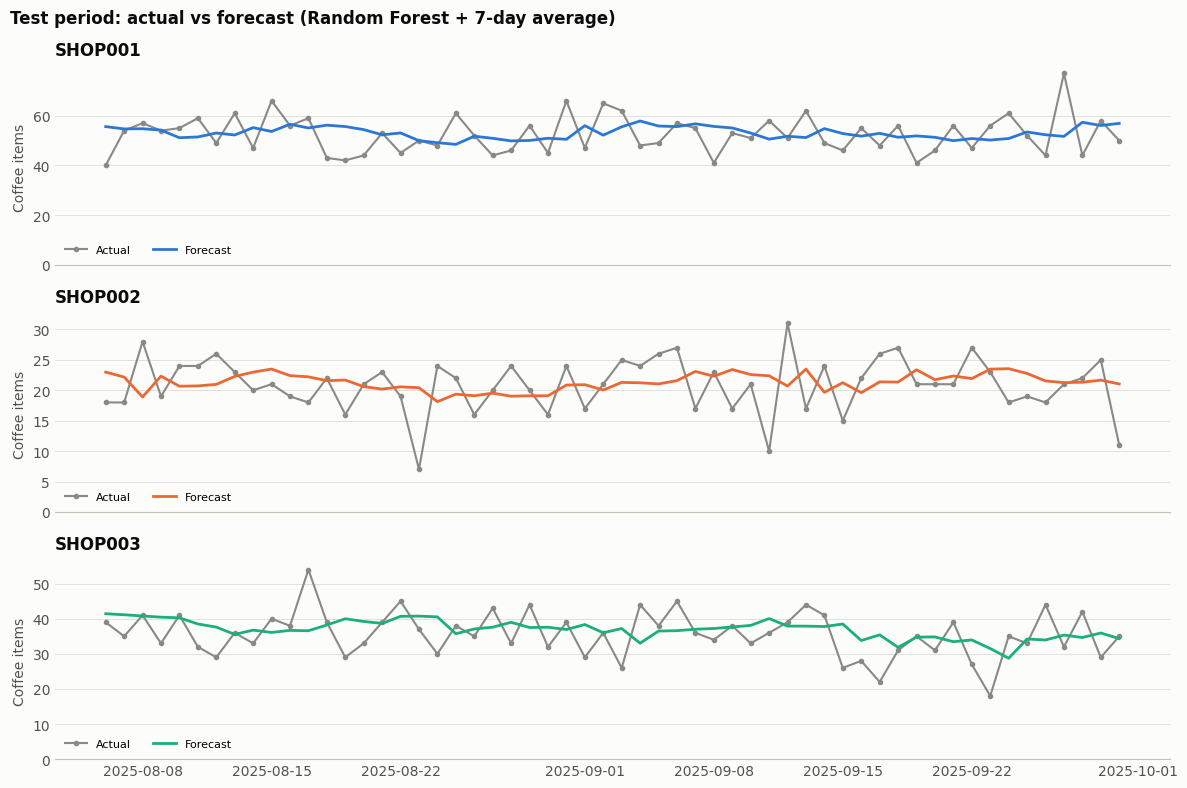

,rata2_aktual,MAE,WAPE_%
Outlet,,,
SHOP001,52.45,6.73,12.83
SHOP002,20.88,3.96,18.96
SHOP003,35.59,5.18,14.54


In [58]:
results = pd.concat([test[["Outlet", "Date", "CoffeeItems"]], test_forecasts], axis=1)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, outlet in zip(axes, OUTLETS):
    r = results.loc[results["Outlet"] == outlet]
    ax.plot(r["Date"], r["CoffeeItems"], color="#8a8983", linewidth=1.5, marker="o", markersize=3, label="Actual")
    ax.plot(r["Date"], r[SELECTED], color=OUTLET_COLORS[outlet], linewidth=2, label="Forecast")
    ax.set_ylim(bottom=0)
    style_axes(ax, outlet, "Coffee items")
    ax.legend(ncol=2, loc="lower left", fontsize=8)
fig.suptitle(f"Test period: actual vs forecast ({SELECTED})", x=0.01, ha="left", weight="bold", color=INK)
fig.tight_layout()
save_figure(fig, "04_test_actual_vs_forecast.png")
plt.show()

per_outlet = results.groupby("Outlet").apply(
    lambda r: pd.Series({"rata2_aktual": r["CoffeeItems"].mean(),
                         "MAE": (r["CoffeeItems"] - r[SELECTED]).abs().mean(),
                         "WAPE_%": (r["CoffeeItems"] - r[SELECTED]).abs().sum() / r["CoffeeItems"].sum() * 100}))
display(per_outlet)

> **Kesimpulan:** Grafik menunjukkan bahwa garis ramalan berhasil mengikuti tingkat penjualan masing-masing cabang dengan baik (SHOP001: MAE **6,73** / WAPE **12,83%**; SHOP003: MAE **5,18** / WAPE **14,54%**; SHOP002: MAE **3,96** / WAPE **18,96%**). Lonjakan atau penurunan tajam yang hanya terjadi satu hari (misalnya di SHOP002 pada 23 Agustus dan pertengahan September) memang tidak tertangkap karena sifatnya acak. Nilai persentase WAPE di SHOP002 terlihat paling besar (18,96%) karena volume penjualan harian cabang ini paling kecil (~21 gelas), sehingga selisih 4 gelas saja sudah bernilai hampir 19%.

### Batas bawah error

Jika penjualan harian benar-benar acak di sekitar rata-rata yang diketahui dengan tepat, berapa error terkecil yang mungkin dicapai? Angka ini menjadi patokan seberapa jauh model masih bisa diperbaiki.


In [59]:
def expected_random_error(mean_level):
    """Rata-rata selisih |aktual - rata2| bila permintaan murni acak (Poisson) di sekitar rata-rata yang diketahui."""
    k = np.arange(0, int(mean_level * 3) + 50)
    return float((poisson.pmf(k, mean_level) * np.abs(k - mean_level)).sum())


floor = results.groupby("Outlet")["CoffeeItems"].mean().map(expected_random_error)
weights = results.groupby("Outlet").size()
floor_mae = float((floor * weights).sum() / weights.sum())
selected_mae = test_scores.loc[SELECTED, "MAE"]

print(f"MAE metode terpilih di data uji          : {selected_mae:.2f} item")
print(f"Batas bawah MAE karena keacakan harian   : {floor_mae:.2f} item")
print(f"Porsi error yang memang tidak terhindarkan: {floor_mae / selected_mae:.0%}")

MAE metode terpilih di data uji          : 5.29 item
Batas bawah MAE karena keacakan harian   : 4.73 item
Porsi error yang memang tidak terhindarkan: 89%


> **Kesimpulan:** Batas bawah MAE akibat keacakan alami kedatangan pembeli adalah **4,73 gelas per hari**. Artinya, **89% dari error metode terpilih kita (4,73 dari 5,29 gelas) adalah keacakan harian yang memang tidak bisa dihilangkan oleh model apa pun**. Ruang perbaikan yang tersisa hanya sekitar 0,56 gelas per hari. Inilah alasan mengapa Random Forest dan rata-rata 7 hari hasilnya hampir sama: keduanya sudah mentok mendekati batas kemampuan data. Oleh sebab itu, peningkatan manfaat bisnis yang paling nyata bukan dari mencari algoritma yang lebih rumit, melainkan dari mengatur **stok cadangan (*buffer*)** secara tepat di Tahap 5.

### Fitur yang paling berpengaruh

Pengaruh tiap fitur diukur dengan *permutation importance*: nilai satu fitur diacak, lalu dilihat seberapa besar MAE memburuk. Semakin besar kenaikannya, semakin penting fitur itu.


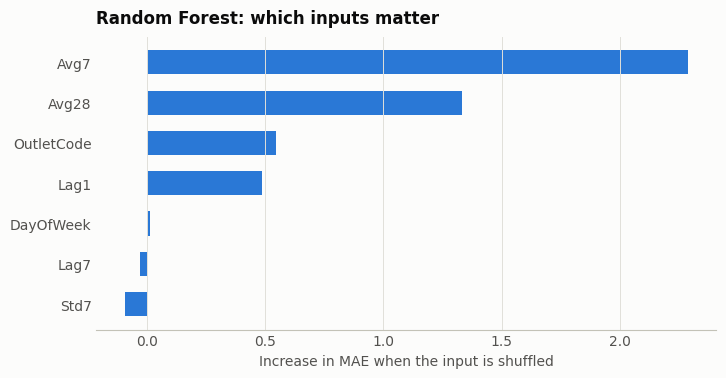

,kenaikan_MAE_jika_fitur_diacak
Avg7,2.29
Avg28,1.33
OutletCode,0.54
Lag1,0.49
DayOfWeek,0.01
Lag7,-0.03
Std7,-0.10


In [60]:
importance = permutation_importance(final_forest, test[FEATURES], test["CoffeeItems"],
                                    scoring="neg_mean_absolute_error", n_repeats=20,
                                    random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.Series(importance.importances_mean, index=FEATURES)
              .sort_values().rename("kenaikan_MAE_jika_fitur_diacak"))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(importance.index, importance.values, color="#2a78d6", height=0.6)
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
style_axes(ax, "Random Forest: which inputs matter", "", "Increase in MAE when the input is shuffled")
save_figure(fig, "05_feature_importance.png")
plt.show()
display(importance.sort_values(ascending=False).to_frame())

> **Kesimpulan:** Fitur yang paling menentukan akurasi Random Forest adalah **rata-rata 7 hari terakhir (`Avg7`, MAE memburuk +2,29 gelas jika diacak)** dan **rata-rata 28 hari (`Avg28`, +1,33 gelas)**, disusul identitas cabang (`OutletCode`, +0,54) dan penjualan kemarin (`Lag1`, +0,49). Sebaliknya, hari dalam minggu (`DayOfWeek`, +0,01), penjualan minggu lalu (`Lag7`, -0,03), dan gejolak mingguan (`Std7`, -0,10) hampir tidak memberi kontribusi. Temuan ini sejalan penuh dengan hasil analisis diagnostik pada bagian 4.2.

### Kelemahan: lambat saat pola berubah mendadak

Karena ramalan bertumpu pada rata-rata beberapa hari terakhir, ramalan butuh waktu untuk menyesuaikan diri ketika level penjualan berubah tiba-tiba.


In [61]:
# Seberapa cepat rata-rata bergerak menyesuaikan diri saat pola berubah mendadak?
def shift_error(outlet, change_date, days=7):
    d = daily.loc[daily["Outlet"] == outlet].set_index("Date")
    err = (d["CoffeeItems"] - d["Avg7"]).abs()
    change_date = pd.Timestamp(change_date)
    first_week = err.loc[change_date: change_date + pd.Timedelta(days=days - 1)].mean()
    after = err.loc[change_date + pd.Timedelta(days=days): change_date + pd.Timedelta(days=27)].mean()
    return pd.Series({"MAE_7_hari_pertama": first_week, "MAE_3_minggu_berikutnya": after})


regime_check = pd.DataFrame({
    "SHOP003, 1 Apr 2025": shift_error("SHOP003", "2025-04-01"),
    "SHOP003, 1 Mei 2025": shift_error("SHOP003", "2025-05-01"),
    "SHOP001, 1 Jun 2025": shift_error("SHOP001", "2025-06-01"),
}).T
display(regime_check)

,MAE_7_hari_pertama,MAE_3_minggu_berikutnya
"SHOP003, 1 Apr 2025",17.06,3.58
"SHOP003, 1 Mei 2025",12.00,5.97
"SHOP001, 1 Jun 2025",17.76,7.29


> **Kesimpulan:** Saat terjadi perubahan pola penjualan secara tiba-tiba (seperti awal April pasca-Lebaran, awal Mei saat kembali normal, dan awal Juni di SHOP001), error pada **7 hari pertama melonjak menjadi 12,00 – 17,76 gelas per hari**, atau sekitar dua sampai lima kali lipat lebih besar dibandingkan tiga minggu setelahnya (**3,58 – 7,29 gelas per hari**). Karena model butuh waktu sekitar satu minggu untuk beradaptasi, maka untuk kejadian kalender yang tanggalnya sudah diketahui pasti (seperti awal Ramadan dan Lebaran), target persiapan **harus disesuaikan secara manual sejak hari pertama** (menjadi Rekomendasi 3 pada bagian berikut).


---
# Tahap 5. Interpretation / Evaluation

## 5.1 Analitik Preskriptif: Apa yang sebaiknya dilakukan?

### Rekomendasi 1. Target persiapan harian = ramalan + buffer per outlet

Ramalan saja tidak cukup karena hampir setengah hari akan berada di atas ramalan. Maka target persiapan ditambah buffer. Besarnya buffer diambil dari error pada validasi silang (bukan dari data uji), dihitung terpisah untuk tiap outlet:

* Target layanan 80%: buffer = persentil ke-80 error validasi
* Target layanan 90%: buffer = persentil ke-90 error validasi
* Target layanan 95%: buffer = persentil ke-95 error validasi

Simulasi dijalankan pada data uji dan dibandingkan dengan dua aturan sederhana yang diberi buffer dengan cara yang sama.

Catatan: data tidak memuat catatan stok habis, sehingga penjualan yang tercatat dianggap sebagai permintaan. "Kekurangan" di sini berarti hari ketika penjualan aktual melebihi target persiapan.

Bagian berikut membandingkan metode terpilih dengan aturan sederhana pada data uji.

In [62]:
def simulate_plan(method, target_level):
    """Rencana persiapan = ramalan + buffer per outlet. Buffer diambil dari error validasi (bukan data uji)."""
    residual = oof["CoffeeItems"] - oof[method]
    buffer = residual.groupby(oof["Outlet"]).quantile(target_level)
    plan = (results[method] + results["Outlet"].map(buffer)).clip(lower=0).round()
    actual = results["CoffeeItems"]
    return {
        "metode": method,
        "target_layanan": target_level,
        "hari_tanpa_kekurangan_%": (actual <= plan).mean() * 100,
        "kelebihan_per_outlet_hari": (plan - actual).clip(lower=0).mean(),
        "kekurangan_per_outlet_hari": (actual - plan).clip(lower=0).mean(),
    }


plan_methods = [SELECTED, "Same day last week", "Historical average"]
plans = pd.DataFrame([simulate_plan(m, q) for m in plan_methods for q in (0.80, 0.90, 0.95)])
display(plans)

,metode,target_layanan,hari_tanpa_kekurangan_%,kelebihan_per_outlet_hari,kekurangan_per_outlet_hari
0,Random Forest + 7-day average,0.80,91.67,8.51,0.39
1,Random Forest + 7-day average,0.90,97.62,12.71,0.12
2,Random Forest + 7-day average,0.95,98.81,15.15,0.07
3,Same day last week,0.80,91.67,11.95,0.46
4,Same day last week,0.90,95.83,15.37,0.21
5,Same day last week,0.95,98.81,20.54,0.05
6,Historical average,0.80,98.81,14.78,0.08
7,Historical average,0.90,99.40,20.39,0.02
8,Historical average,0.95,99.40,22.38,0.01


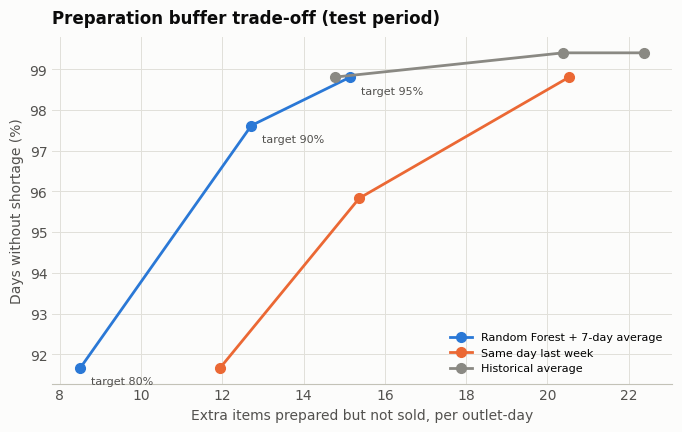

In [63]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plan_colors = {SELECTED: "#2a78d6", "Same day last week": "#eb6834", "Historical average": "#8a8983"}
for method in plan_methods:
    p = plans.loc[plans["metode"] == method]
    ax.plot(p["kelebihan_per_outlet_hari"], p["hari_tanpa_kekurangan_%"], color=plan_colors[method],
            linewidth=2, marker="o", markersize=7, label=method)
sel = plans.loc[plans["metode"] == SELECTED]
for _, row in sel.iterrows():
    ax.annotate(f"target {row['target_layanan']:.0%}", (row["kelebihan_per_outlet_hari"], row["hari_tanpa_kekurangan_%"]),
                xytext=(8, -12), textcoords="offset points", fontsize=8, color=MUTED)
ax.grid(axis="x", color=GRID)
style_axes(ax, "Preparation buffer trade-off (test period)", "Days without shortage (%)",
           "Extra items prepared but not sold, per outlet-day")
ax.legend(loc="lower right", fontsize=8)
save_figure(fig, "06_buffer_tradeoff.png")
plt.show()

> **Kesimpulan:** Grafik memperlihatkan pertukaran (*trade-off*) antara keamanan ketersediaan stok (sumbu tegak: % hari tanpa kekurangan) dan kelebihan bahan yang tidak terjual (sumbu mendatar). Semakin berada di **kiri atas**, semakin bagus suatu metode karena mampu menjaga stok tetap aman dengan sisa berlebih yang lebih sedikit. Terlihat garis biru (**Random Forest + 7-day average**) selalu berada di sebelah kiri garis oranye (aturan *"Same day last week"*) pada seluruh tingkat layanan (80%, 90%, maupun 95%).


In [64]:
at90 = plans.loc[plans["target_layanan"] == 0.90].set_index("metode")
excess_selected = at90.loc[SELECTED, "kelebihan_per_outlet_hari"]
excess_rule = at90.loc["Same day last week", "kelebihan_per_outlet_hari"]
excess_saved = excess_rule - excess_selected
outlet_days_per_month = len(OUTLETS) * 30
items_saved_per_month = excess_saved * outlet_days_per_month

print("Target layanan 90%: metode terpilih dibanding aturan 'hari yang sama minggu lalu'")
print(f"  Hari tanpa kekurangan       : {at90.loc[SELECTED, 'hari_tanpa_kekurangan_%']:.1f}% vs "
      f"{at90.loc['Same day last week', 'hari_tanpa_kekurangan_%']:.1f}%")
print(f"  Kelebihan persiapan per hari: {excess_selected:.1f} vs {excess_rule:.1f} item per outlet "
      f"(turun {excess_saved / excess_rule:.0%})")
print(f"  Kelebihan yang dihemat      : sekitar {items_saved_per_month:,.0f} item per bulan (3 outlet)")

Target layanan 90%: metode terpilih dibanding aturan 'hari yang sama minggu lalu'
  Hari tanpa kekurangan       : 97.6% vs 95.8%
  Kelebihan persiapan per hari: 12.7 vs 15.4 item per outlet (turun 17%)
  Kelebihan yang dihemat      : sekitar 239 item per bulan (3 outlet)


> **Kesimpulan:** Pada target layanan **90%**, metode terpilih kita memberikan hasil yang lebih unggul di kedua sisi dibandingkan aturan praktis *"hari yang sama minggu lalu"*:
> * **Stok lebih aman:** mencapai **97,6% hari tanpa kekurangan** (dibanding **95,8%** pada aturan minggu lalu, sehingga hari yang mengalami kekurangan turun dari 4,2% menjadi 2,4%).
> * **Kelebihan persiapan lebih hemat 17%:** rata-rata kelebihan persiapan turun dari **15,4 menjadi 12,7 gelas per outlet per hari**, atau menghemat sekitar **239 porsi persiapan berlebih per bulan** di tiga outlet.
> * Karena dataset tidak memuat harga modal bahan baku per gelas, penghematan ini dilaporkan secara jujur dalam satuan fisik (jumlah item dan persen hari), bukan menggunakan asumsi rupiah.

### Rekomendasi 2. Bagi target harian per shift dan kuatkan shift malam

Porsi per shift dihitung dari empat minggu sebelum periode uji, lalu dicek ulang pada data uji.


In [65]:
# Porsi shift dihitung dari 4 minggu terakhir sebelum data uji, lalu dicek ulang pada data uji.
reference = coffee.loc[(coffee["Date"] >= test_start - pd.Timedelta(days=28)) & (coffee["Date"] < test_start)]
share_before = pd.crosstab(reference["Outlet"], reference["Shift"], normalize="index")
share_test = pd.crosstab(coffee.loc[coffee["Date"] >= test_start, "Outlet"],
                         coffee.loc[coffee["Date"] >= test_start, "Shift"], normalize="index")
print("Porsi permintaan per shift (4 minggu sebelum uji):")
display(share_before.style.format("{:.1%}"))
print("Selisih terbesar dengan porsi di data uji:", f"{(share_before - share_test).abs().max().max():.1%}")

# Contoh rencana satu hari: ramalan rata-rata per outlet pada data uji, dibagi menurut porsi shift.
typical_forecast = results.groupby("Outlet")[SELECTED].mean()
buffer90 = (oof["CoffeeItems"] - oof[SELECTED]).groupby(oof["Outlet"]).quantile(0.90)
shift_plan = share_before.mul(typical_forecast + buffer90, axis=0).round()
shift_plan["Total"] = shift_plan.sum(axis=1)
print("\nContoh target persiapan per shift (ramalan + buffer 90%), dalam item kopi:")
display(shift_plan.astype(int))

evening_vs_day = per_hour["Evening 18-22"] / per_hour[["Morning 07-10", "Midday 11-14"]].mean(axis=1) - 1
print("Permintaan per jam pada shift malam dibanding pagi-siang:")
print(evening_vs_day.map("{:+.0%}".format).to_string())

Porsi permintaan per shift (4 minggu sebelum uji):


Shift,Morning 07-10,Midday 11-14,Afternoon 15-17,Evening 18-22
Outlet,,,,
SHOP001,26.0%,25.7%,17.5%,30.8%
SHOP002,26.7%,24.4%,17.7%,31.2%
SHOP003,14.4%,28.3%,20.3%,37.0%


Selisih terbesar dengan porsi di data uji: 2.3%

Contoh target persiapan per shift (ramalan + buffer 90%), dalam item kopi:


Shift,Morning 07-10,Midday 11-14,Afternoon 15-17,Evening 18-22,Total
Outlet,,,,,
SHOP001,17,17,12,20,66
SHOP002,8,7,5,9,29
SHOP003,7,14,10,19,50


Permintaan per jam pada shift malam dibanding pagi-siang:
Outlet
SHOP001    +23%
SHOP002    +19%
SHOP003    +17%


> **Kesimpulan:**
> * **Proporsi shift sangat stabil:** selisih porsi shift antara 4 minggu sebelum uji dan periode uji paling besar hanya **2,3 poin persen**, sehingga pembagian ini aman dipakai sebagai patokan harian.
> * **Perkuat persiapan sebelum shift malam:** karena shift malam (18.00–22.59) memiliki permintaan per jam tertinggi di semua cabang (**+23%** di SHOP001, **+19%** di SHOP002, dan **+17%** di SHOP003 dibanding rata-rata pagi-siang), pengisian ulang susu, *cold brew*, dan es serta jam istirahat barista sebaiknya diselesaikan **sebelum pukul 17.00**.
> * **Khusus SHOP003** yang baru buka pukul 09.00, target shift pagi cukup kecil (sekitar **7 gelas** dari total 50 gelas), sedangkan beban utama ada di siang (**14 gelas**) dan malam (**19 gelas**).

### Rekomendasi 3. Kalender penyesuaian musiman per outlet

Karena model membutuhkan waktu sekitar satu minggu untuk menyesuaikan diri setelah perubahan mendadak (lihat bagian 4.3), maka untuk periode musiman yang tanggalnya sudah diketahui, target persiapan sebaiknya disesuaikan secara manual sejak hari pertama berdasarkan pola tahun 2025:

| Periode | Outlet | Penyesuaian target persiapan (berdasarkan pola 2025 di bagian 4.2) |
|---|---|---|
| Awal Ramadan (sebulan penuh) | SHOP002, SHOP003 | Pangkas target siang (sebelum 16.00) sekitar **60%**; alihkan persiapan dan personel ke sore-malam (target malam SHOP003 naik sekitar **1,8 kali** lipat dari Februari, SHOP002 naik sekitar **1,5 kali** lipat) |
| Sebulan setelah Idulfitri | SHOP003 | Turunkan target harian menjadi sekitar **43% – 45%** dari bulan normal |
| Sebulan setelah Idulfitri | SHOP002 | Turunkan target harian menjadi sekitar **74% – 75%** dari bulan normal |
| Sepanjang Ramadan & Lebaran | SHOP001 | **Tidak perlu penyesuaian khusus** (tetap gunakan ramalan normal karena indeks bulanan stabil di 1,00 – 1,02) |
| Periode Juni – Juli | Semua outlet | Siapkan kapasitas bahan lebih tinggi (**1,1 – 1,5 kali** normal, tertinggi di SHOP002); konfirmasi penyebab lonjakan malam bulan Juni di SHOP001 ke pengelola cabang |

### Rekomendasi 4. Uji coba dan pemantauan

1. **Uji coba 4 minggu di SHOP001** (outlet terbesar dan paling stabil): setiap malam kirimkan angka ramalan, *buffer* 90%, dan pembagian per shift ke kepala outlet.
2. **Ukuran keberhasilan:** bandingkan jumlah hari stok habis, jumlah bahan terbuang, dan WAPE mingguan selama 4 minggu uji coba terhadap 4 minggu sebelumnya.
3. **Mulai mencatat stok habis dan bahan terbuang setiap hari** beserta harga modal bahan per gelas. Dengan catatan ini, penghematan rupiah yang sebenarnya dapat dihitung secara pasti.
4. **Pemantauan model:** jika WAPE satu minggu melebihi 20%, periksa apakah ada kejadian khusus di cabang. Latih ulang model setiap akhir bulan.

## 5.2 Keterbatasan

* **Tidak ada data stok habis (*stock-out*).** Pada hari ketika bahan habis lebih cepat, penjualan yang tercatat lebih rendah daripada permintaan sebenarnya.
* **Tidak ada data biaya bahan baku dan margin.** Dampak perbaikan dinyatakan secara jujur dalam satuan fisik (jumlah item dan persen hari), tidak dalam rupiah.
* **Kaitan dengan Ramadan dan Lebaran** disimpulkan dari kecocokan tanggal kalender 2025, bukan dari kolom penanda khusus di dalam data, sehingga tetap perlu dikonfirmasi ke pengelola outlet.
* **Cakupan data baru satu tahun (9 bulan: Januari–September 2025),** sehingga pola musiman di atas perlu diuji ulang ketika data tahun kedua sudah tersedia.
* **Lonjakan malam hari di SHOP001 pada bulan Juni** (21,2 menjadi 52,6 gelas/hari) belum dapat dijelaskan dari kolom transaksi yang ada.

## 5.3 Ringkasan angka untuk infografik

Tabel berikut mengumpulkan angka utama dari seluruh notebook dan menyimpannya ke `hasil_notebook/angka_kunci_infografik.csv`.


In [66]:
key_numbers = pd.Series({
    "Periode data": f"{transactions['Date'].min().date()} s.d. {transactions['Date'].max().date()}",
    "Jumlah struk": f"{len(transactions):,}",
    "Jumlah item kopi": f"{len(coffee):,}",
    "Porsi struk berisi kopi": f"{coffee['ReceiptNumber'].nunique() / len(transactions):.1%}",
    "Rata-rata kopi per outlet per hari": f"{daily['CoffeeItems'].mean():.1f}",
    "Porsi permintaan shift malam (18-22), seluruh outlet": f"{(coffee['Shift'] == 'Evening 18-22').mean():.1%}",
    "Metode terpilih": SELECTED,
    "MAE uji (item per outlet-hari)": f"{test_scores.loc[SELECTED, 'MAE']:.2f}",
    "WAPE uji": f"{test_scores.loc[SELECTED, 'WAPE_%']:.1f}%",
    "WAPE aturan 'minggu lalu'": f"{test_scores.loc['Same day last week', 'WAPE_%']:.1f}%",
    "WAPE rata-rata historis": f"{test_scores.loc['Historical average', 'WAPE_%']:.1f}%",
    "Batas bawah MAE (keacakan harian)": f"{floor_mae:.2f}",
    "Hari tanpa kekurangan (target 90%)": f"{at90.loc[SELECTED, 'hari_tanpa_kekurangan_%']:.1f}%",
    "Penurunan kelebihan persiapan vs aturan 'minggu lalu'": f"{excess_saved / excess_rule:.0%}",
    "Kelebihan persiapan yang dihemat per bulan": f"{items_saved_per_month:,.0f} item",
})
display(key_numbers.to_frame("nilai"))
key_numbers.to_frame("nilai").to_csv(OUTPUT_DIR / "angka_kunci_infografik.csv")
test_scores.to_csv(OUTPUT_DIR / "hasil_uji_model.csv")
plans.to_csv(OUTPUT_DIR / "simulasi_buffer.csv", index=False)
print("Tersimpan di", OUTPUT_DIR.resolve())

,nilai
Periode data,2025-01-02 s.d. 2025-09-30
Jumlah struk,"53,820"
Jumlah item kopi,"31,068"
Porsi struk berisi kopi,54.0%
Rata-rata kopi per outlet per hari,38.1
"Porsi permintaan shift malam (18-22), seluruh outlet",36.5%
Metode terpilih,Random Forest + 7-day average
MAE uji (item per outlet-hari),5.29
WAPE uji,14.6%
WAPE aturan 'minggu lalu',19.2%


Tersimpan di D:\UTS ANALISA BISNIS\hasil_notebook


---
## Kesimpulan

1. **Analitik Deskriptif (*Apa yang terjadi?*):** Dari 53.820 struk selama Januari–September 2025 (272 hari), terjual **31.068 gelas minuman kopi** (ada di **54,0%** struk) dengan rata-rata **38,1 gelas per outlet per hari**. **SHOP001** menyumbang hampir separuh penjualan (**48,7%**; 55,6 gelas/hari), diikuti **SHOP003** (**30,9%**; 35,3 gelas/hari) dan **SHOP002** (**20,4%**; 23,3 gelas/hari). Penjualan menyebar merata di 47 menu (menu terlaris hanya 2,3%), dan waktu terpadat berada pada **shift malam (18.00–22.59)** yang menyumbang **36,5%** penjualan harian (**17% – 23% lebih ramai per jam** dibanding pagi-siang).
2. **Analitik Diagnostik (*Mengapa itu terjadi?*):** Naik-turunnya penjualan kopi digerakkan oleh jumlah pengunjung kafe (korelasi struk dengan kopi **0,84 – 0,91**), sedangkan porsi struk yang membeli kopi selalu stabil (**52% – 57%** setiap bulan). Perubahan tajam terjadi di **SHOP002 dan SHOP003** yang bertepatan dengan **Ramadan** (penjualan sebelum pukul 16.00 turun ~61%, sedangkan sore-malam melonjak hingga +85% di SHOP003) serta sebulan setelah **Idulfitri** (penjualan April turun ke 43% di SHOP003 dan 74% di SHOP002), sementara **SHOP001 tidak terpengaruh**. Di luar perubahan musiman tersebut, variasi harian sebesar **5 – 7 gelas per hari** bersifat acak alami (rasio simpangan baku terhadap akar rata-rata **0,98 – 1,07**), sehingga penjualan harian paling erat kaitannya dengan **rata-rata 7 hari terakhir (`Avg7`)**.
3. **Analitik Prediktif (*Apa yang akan terjadi?*):** Melalui validasi silang 5 fold berurutan waktu, kombinasi **Random Forest + 7-day average** terpilih sebagai metode terbaik. Pada data uji 8 minggu terakhir, metode ini mencatat **MAE 5,29 gelas per outlet per hari** (**RMSE 6,78**; **WAPE 14,6%**), atau **24% lebih akurat** dibanding aturan praktis *"hari yang sama minggu lalu"* (WAPE 19,2%) dan **57% lebih akurat** dibanding rata-rata historis (WAPE 34,2%). Sekitar **89%** dari sisa error model (4,73 dari 5,29 gelas) merupakan batas bawah keacakan harian yang tidak bisa dihilangkan oleh algoritma mana pun, dan model rata-rata bergerak membutuhkan waktu sekitar **1 minggu** untuk beradaptasi saat terjadi perubahan mendadak.
4. **Analitik Preskriptif (*Apa yang sebaiknya dilakukan?*):** Terapkan empat langkah operasional: **(a)** tetapkan target persiapan harian sebesar **ramalan + *buffer* persentil ke-90 per outlet**, yang pada simulasi data uji terbukti menjaga **97,6% hari tanpa kekurangan stok** sekaligus **mengurangi kelebihan persiapan sebesar 17%** (**~239 gelas berlebih lebih sedikit per bulan** di 3 outlet dibanding aturan minggu lalu); **(b)** bagi target harian ke dalam 4 shift dan selesaikan pengisian ulang bahan serta istirahat barista sebelum pukul 17.00 untuk menghadapi puncak shift malam; **(c)** berlakukan penyesuaian manual sejak hari pertama Ramadan dan pasca-Idulfitri khusus di SHOP002 dan SHOP003; serta **(d)** jalankan **uji coba 4 minggu di SHOP001** sambil mulai mencatat kejadian stok habis, bahan terbuang, dan biaya bahan per gelas setiap hari.
